# 04 · Statistical comparison of v2.0 vs v1.0

**Primary estimator:** difference-in-differences on device-level KPIs,
`DiD = mean(post - pre | treatment) - mean(post - pre | control)`, with
* a Welch t-test on the device deltas (primary p-value) plus a Mann-Whitney check,
* a 95% bootstrap CI,
* an OLS `metric ~ treated * post` with device-clustered standard errors as a cross-check,
* Benjamini-Hochberg FDR correction across the eight metrics.

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
P = ROOT / "data" / "processed"

In [2]:
from src.performance_metrics import device_period_kpis
from src.statistical_tests import compare_firmware, compare_by_segment, naive_comparison, event_rate_tests
tel = pd.read_parquet(P / "telemetry.parquet"); kpis = device_period_kpis(tel)
overall = compare_firmware(kpis)
overall[["label", "treatment_pre", "did", "ci_low", "ci_high", "relative_change_pct", "p_value_adj", "p_value_ols_cluster", "verdict"]]

,label,treatment_pre,did,ci_low,ci_high,relative_change_pct,p_value_adj,p_value_ols_cluster,verdict
0,Firmware errors / 100 intervals,4.2120,0.3949,-0.7989,1.5133,9.3763,6.0240e-01,5.0608e-01,no significant change
1,Uptime %,99.4323,0.3633,-0.8218,1.8188,0.3654,6.0240e-01,6.0225e-01,no significant change
2,Reboots / 100 intervals,0.1178,0.1721,0.0217,0.3237,146.1538,7.3766e-02,2.6361e-02,no significant change
3,Sensor jitter (rel. step-to-step change),0.0143,-0.0087,-0.0107,-0.0071,-61.0036,7.8593e-16,7.3392e-21,improved
4,Mean vibration RMS (g),0.0872,0.0037,0.0017,0.0057,4.1927,2.2064e-03,4.0414e-04,regressed
5,Vibration alarm rate %,2.5906,-1.0640,-4.6106,2.0029,-41.0723,6.0240e-01,5.3974e-01,no significant change
6,Median response time (ms),45.7772,-1.1676,-2.5765,0.3162,-2.5505,1.8996e-01,1.1637e-01,no significant change
7,P95 response time (ms),49.0755,-1.4850,-2.9884,0.0766,-3.0259,1.2430e-01,5.9789e-02,no significant change


### Pitfall 1: the naive before/after comparison
Comparing updated devices only with their own past mixes the firmware effect with bearing wear and latency incidents
over the same period.

In [3]:
naive = pd.DataFrame([naive_comparison(kpis, m) for m in overall.metric])
naive.merge(overall[["metric", "did"]], on="metric")

,metric,pre,post,naive_diff,p_value,did
0,fw_errors_per_100,4.2120,4.7736,0.5616,1.9967e-01,0.3949
1,uptime_pct,99.4323,99.3643,-0.0680,9.0200e-01,0.3633
2,reboots_per_100,0.1178,0.2899,0.1721,3.2520e-03,0.1721
3,sensor_jitter,0.0143,0.0063,-0.0080,7.3059e-18,-0.0087
4,mean_rms,0.0872,0.0915,0.0043,1.4796e-05,0.0037
5,alarm_rate_pct,2.5906,3.1793,0.5888,6.3246e-01,-1.0640
6,p50_response_ms,45.7772,44.6497,-1.1274,1.2889e-01,-1.1676
7,p95_response_ms,49.0755,47.7399,-1.3357,8.9793e-02,-1.4850


### Pitfall 2: fleet averages hide segment regressions
Rev A improves and rev B regresses, so at fleet level the two partly cancel.

In [4]:
seg = compare_by_segment(kpis, "hw_revision")
seg.pivot(index="label", columns="segment", values=["relative_change_pct", "p_value_adj", "verdict"])

relative_change_pct                 p_value_adj                              verdict                       
segment                                        hw_revision=A hw_revision=B hw_revision=A hw_revision=B          hw_revision=A          hw_revision=B
label                                                                                                                                               
Firmware errors / 100 intervals                      -45.512      161.8843        0.0021           0.0               improved              regressed
Mean vibration RMS (g)                                2.8025         7.929        0.0562        0.0045  no significant change              regressed
Median response time (ms)                           -12.1652       22.2071           0.0           0.0               improved              regressed
P95 response time (ms)                              -12.6426       21.6752           0.0           0.0               improved              regressed
Reboots / 100 intervals                                 60.0         200.0        0.6447        0.0045  no significant change              regressed
Sensor jitter (rel. step-to-step change)            -63.6397      -53.9725           0.0           0.0               improved               improved
Uptime %                                              0.7306       -0.5551        0.5183        0.0761  no significant change  no significant change
Vibration alarm rate %                              -82.3804      124.5614        0.3994        0.2627  no significant change  no significant change

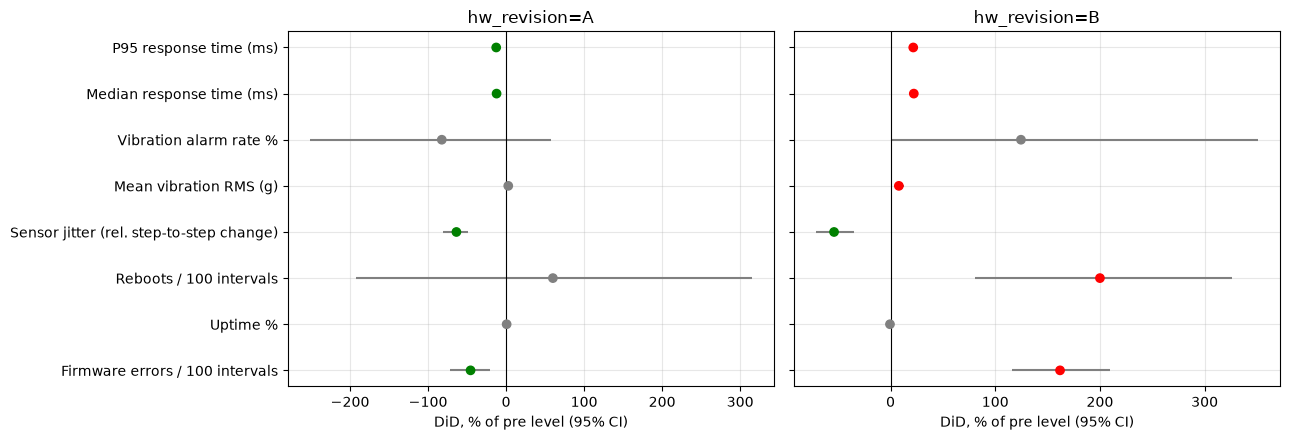

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (s, g) in zip(axes, seg.groupby("segment")):
    rel = lambda v: 100 * v / g.treatment_pre
    c = g.verdict.map({"improved": "green", "regressed": "red"}).fillna("grey")
    ax.errorbar(rel(g.did), g.label, xerr=[rel(g.did) - rel(g.ci_low), rel(g.ci_high) - rel(g.did)], fmt="none", ecolor="grey")
    ax.scatter(rel(g.did), g.label, c=c, zorder=3); ax.axvline(0, color="k", lw=0.8); ax.set_title(s)
    ax.set_xlabel("DiD, % of pre level (95% CI)")
plt.tight_layout()

### Exact rate tests on event counts (post period, v2.0 vs v1.0 intervals)

In [6]:
event_rate_tests(tel)

,segment,event,v1_events,v1_intervals,v2_events,v2_intervals,rate_ratio,ci_low,ci_high,p_value
0,all,fw_error_count,346,7200,527,11040,0.9933,0.8657,1.1409,9.4480e-01
1,all,reboot,7,7200,32,11040,2.9814,1.2926,8.0030,5.0942e-03
2,hw_revision=A,fw_error_count,267,5160,237,7920,0.5783,0.4834,0.6915,1.0677e-09
3,hw_revision=A,reboot,6,5160,8,7920,0.8687,0.2643,3.0375,7.9072e-01
4,hw_revision=B,fw_error_count,79,2040,290,3120,2.4002,1.8656,3.1185,1.5354e-13
5,hw_revision=B,reboot,1,2040,24,3120,15.6923,2.5589,645.3117,1.0375e-04


In [7]:
for seg_name in ["region", "hw_revision"]:
    r = compare_by_segment(kpis, seg_name)
    print(r[r.verdict == "regressed"][["segment", "label", "relative_change_pct", "p_value_adj"]].to_string(index=False), "\n")

       segment                  label  relative_change_pct  p_value_adj
region=NA-East Mean vibration RMS (g)               4.4997       0.0062 



      segment                           label  relative_change_pct  p_value_adj
hw_revision=B Firmware errors / 100 intervals             161.8843   2.2239e-07
hw_revision=B         Reboots / 100 intervals             200.0000   4.5283e-03
hw_revision=B          Mean vibration RMS (g)               7.9290   4.5283e-03
hw_revision=B       Median response time (ms)              22.2071   2.2896e-30
hw_revision=B          P95 response time (ms)              21.6752   2.2896e-30 



Region shows no regression pattern of its own; rev-B devices are spread across regions, which is why every region
inherits some of the rev-B regression. Hardware revision is the variable that separates good from bad outcomes.